# Dados e qualidade dos preços de itens CS:GO

Antes de qualquer análise, a tese precisa mostrar que os preços limpos são confiáveis. Este caderno segue a
ordem do dado: a auditoria da limpeza, a cobertura no tempo, a persistência e a seleção dos itens, a
qualidade da tabela limpa, os saltos de preço, a liquidez dos itens e a comparação com outras fontes de preço.

In [1]:
from argparse import ArgumentParser
from pathlib import Path

import altair as alt
import polars as pl
from great_tables import GT
from helpers.activity import activity_summary
from helpers.audit import audit_metrics
from helpers.coverage import coverage_by_day, coverage_daily, coverage_items, launch_period_groups, quality_metrics
from helpers.export import inline_table_styles, write_outputs
from helpers.formatting import DEC_MARK, SEP_MARK, cap_text, metric_text_table
from helpers.jumps import jump_days, jump_summary
from helpers.params import load_params
from helpers.paths import repo
from helpers.runtime import notebook_arguments
from helpers.schemas import read_table
from helpers.sources import source_comparison

In [2]:
# GitHub shows PNG output but not Vega-Lite.
alt.renderers.enable("png")

# GitHub drops style blocks, so the tables keep their styles inline.
inline_table_styles()

WIDE_TABLES = frozenset({"selection", "sources"})

TOP_JUMP_DAYS = 10

CAP_TEXT = cap_text()

CLEAN_PARAMS = load_params()["clean"]

AUDIT_LABELS = {
    "raw_rows": "Linhas brutas",
    "raw_assets": "Itens brutos",
    "snapshot_days": "Dias com preço positivo",
    "dropped_days": "Dias descartados (poucos preços)",
    "daily_rows": "Linhas com preço positivo, em dias aproveitados",
    "daily_assets": "Itens com preço positivo",
    "selected_assets": "Itens selecionados pelo treino",
    "selected_daily_rows": "Linhas dos itens selecionados",
    "valid_rows": "Linhas dentro dos limites de preço",
    "bounds_removed_rows": "Linhas removidas pelos limites de preço",
    "valid_assets": "Itens com linha válida",
    "cleaned_rows": "Linhas limpas",
    "unchanged_daily_share": "Dias com preço igual ao do dia anterior com preço",
    "longest_unchanged_run": "Maior sequência de preços iguais (dias)",
    f"assets_with_run_over_{CLEAN_PARAMS['max_unchanged_days']}_days": (
        f"Itens com sequência acima de {CLEAN_PARAMS['max_unchanged_days']} dias"
    ),
    "rows_without_return_share": "Linhas sem retorno",
    "daily_jumps": "Saltos diários (o preço dobra ou cai pela metade)",
    "reversed_jumps": "Saltos revertidos",
    "capped_returns": f"Retornos limitados em {CAP_TEXT}",
    "assets_below_one": "Itens com preço médio abaixo de US$ 1",
    "missing_rarity_share": "Linhas sem raridade",
}

AUDIT_FORMATS = {
    "raw_rows": "d",
    "raw_assets": "d",
    "snapshot_days": "d",
    "dropped_days": "d",
    "daily_rows": "d",
    "daily_assets": "d",
    "selected_assets": "d",
    "selected_daily_rows": "d",
    "valid_rows": "d",
    "bounds_removed_rows": "d",
    "valid_assets": "d",
    "cleaned_rows": "d",
    "unchanged_daily_share": ".2%",
    "longest_unchanged_run": "d",
    f"assets_with_run_over_{CLEAN_PARAMS['max_unchanged_days']}_days": "d",
    "rows_without_return_share": ".2%",
    "daily_jumps": "d",
    "reversed_jumps": "d",
    "capped_returns": "d",
    "assets_below_one": "d",
    "missing_rarity_share": ".2%",
}

DAILY_LABELS = {
    "first_price_day": "Primeiro dia com preço",
    "first_return_day": "Primeiro dia com retorno",
    "last_price_day": "Último dia com preço",
    "price_days": "Dias com preço",
    "return_row_share": "Itens-dia com retorno",
    "min_assets_per_day": "Mín. ativos/dia",
    "avg_assets_per_day": "Média ativos/dia",
    "max_assets_per_day": "Máx. ativos/dia",
}

DAILY_FORMATS = {
    "first_price_day": "%d/%m/%Y",
    "first_return_day": "%d/%m/%Y",
    "last_price_day": "%d/%m/%Y",
    "price_days": "d",
    "return_row_share": ".2%",
    "min_assets_per_day": "d",
    "avg_assets_per_day": ".0f",
    "max_assets_per_day": "d",
}

INTEGER_SELECTION_COLUMNS = [
    "assets",
    "selected",
    "low_price",
    "few_observations",
    "no_training_data",
]

METRIC_LABELS = {
    "records": "Registros",
    "assets": "Ativos distintos",
    "days": "Dias distintos",
    "min_days_per_asset": "Mín. dias/ativo",
    "avg_days_per_asset": "Média dias/ativo",
    "max_days_per_asset": "Máx. dias/ativo",
    "positive_return_days": "Dias com retorno positivo",
    "negative_return_days": "Dias com retorno negativo",
    "zero_return_days": "Dias com retorno zero",
    "days_without_return": "Registros sem retorno",
}

METRIC_FORMATS = {
    "records": "d",
    "assets": "d",
    "days": "d",
    "min_days_per_asset": "d",
    "avg_days_per_asset": ".1f",
    "max_days_per_asset": "d",
    "positive_return_days": "d",
    "negative_return_days": "d",
    "zero_return_days": "d",
    "days_without_return": "d",
}

DIRECTION_LABELS = {"up": "Alta: o preço dobra ou mais", "down": "Queda: o preço cai pela metade ou mais"}

SOURCE_LABELS = {
    "steam_7d": "Média de 7 dias (Steam)",
    "composite": "Índice csgotrader (todos os itens)",
    "composite_800": "Índice csgotrader (preço ≥ US$ 800)",
    "buff": "BUFF (menor oferta)",
}

## Argumentos da linha de comando

Os caminhos têm valores padrão a partir da raiz do repositório. Por isso o mesmo caderno roda no
JupyterLab sem argumentos e no terminal com argumentos validados.

In [3]:
parser = ArgumentParser(description="Dados e qualidade: audita a limpeza e descreve a tabela limpa.")
parser.add_argument("--prices", type=Path, default=repo() / "files/prices.parquet", help="Preços diários limpos.")
parser.add_argument("--assets", type=Path, default=repo() / "files/assets.parquet", help="Universo de ativos.")
parser.add_argument("--audit", type=Path, default=repo() / "files/audit.parquet", help="Diagnóstico da limpeza.")
parser.add_argument("--tables", type=Path, default=repo() / "output/tables", help="Pasta para os arquivos das tabelas.")
parser.add_argument("--images", type=Path, default=repo() / "output/images", help="Pasta para os gráficos.")
args = parser.parse_args(notebook_arguments())

In [4]:
prices = read_table("prices", args.prices)
assets = read_table("assets", args.assets)

## Auditar a limpeza

A auditoria compara cada etapa da limpeza com a tabela diária final. Ela mostra quantas linhas e
quantos ativos cada filtro remove, e responde se a limpeza muda a amostra além do esperado.

In [5]:
audit = audit_metrics(read_table("audit", args.audit), prices)
audit_text = metric_text_table(audit, AUDIT_LABELS, AUDIT_FORMATS)

audit_gt = (
    GT(audit_text)
    .tab_header(title="Auditoria da Limpeza — CS:GO")
    .cols_label(metric_name="Métrica", metric_value="Valor")
    .tab_source_note(
        "Linhas e itens depois de cada etapa da limpeza. Preço: média das vendas da Steam nas últimas 24 horas. "
        "Dia descartado: menos preços positivos que a metade do dia mediano, sinal de captura incompleta. "
        "Salto: o preço dobra ou cai pela metade de um dia com preço para o seguinte. Um salto reverte quando o "
        "preço seguinte fica entre 75% e 125% do preço anterior ao salto."
    )
)
audit_gt

"Linhas e itens depois de cada etapa da limpeza. Preço: média das vendas da Steam nas últimas 24 horas. Dia descartado: menos preços positivos que a metade do dia mediano, sinal de captura incompleta. Salto: o preço dobra ou cai pela metade de um dia com preço para o seguinte. Um salto reverte quando o preço seguinte fica entre 75% e 125% do preço anterior ao salto."


## Mostrar a cobertura no tempo

A cobertura diz quantos itens têm preço em cada dia e em que parcela dos itens-dia há retorno. Quedas
bruscas no gráfico apontam capturas incompletas da fonte.

In [6]:
coverage = coverage_daily(prices, audit)

coverage_gt = (
    GT(metric_text_table(coverage, DAILY_LABELS, DAILY_FORMATS))
    .tab_header(title="Cobertura Temporal — CS:GO")
    .cols_label(metric_name="Métrica", metric_value="Valor")
)
coverage_gt

GT(_tbl_data=shape: (8, 2)
┌──────────────────────────┬──────────────┐
│ metric_name              ┆ metric_value │
│ ---                      ┆ ---          │
│ str                      ┆ str          │
╞══════════════════════════╪══════════════╡
│ Primeiro dia com preço   ┆ 02/11/2020   │
│ Primeiro dia com retorno ┆ 03/11/2020   │
│ Último dia com preço     ┆ 30/10/2023   │
│ Dias com preço           ┆ 1.021        │
│ Itens-dia com retorno    ┆ 84,81%       │
│ Mín. ativos/dia          ┆ 1.579        │
│ Média ativos/dia         ┆ 5.002        │
│ Máx. ativos/dia          ┆ 5.817        │
└──────────────────────────┴──────────────┘, _body=<great_tables._gt_data.Body object at 0x78a059d1d940>, _boxhead=Boxhead([ColInfo(var='metric_name', type=<ColInfoTypeEnum.default: 1>, column_label='Métrica', column_align='left', column_width=None), ColInfo(var='metric_value', type=<ColInfoTypeEnum.default: 1>, column_label='Valor', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x78a059d0e990>, _spanners=Spanners([]), _heading=Heading(title='Cobertura Temporal — CS:GO', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x78a059d0ead0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x78a059d1df30>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x78a059d0e710>, _formats=[], _substitutions=[], _col_merge=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='table', type='value', value=

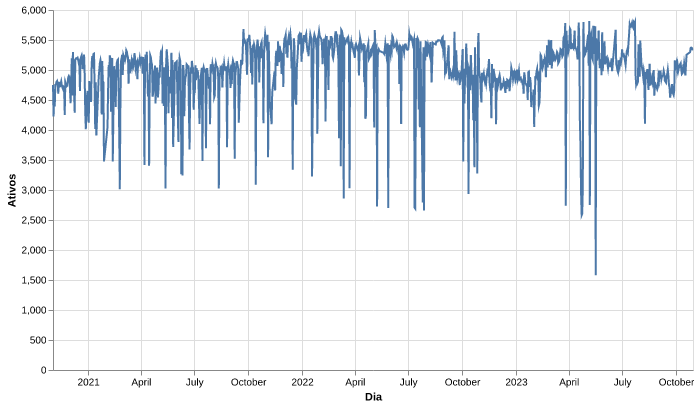

In [7]:
coverage_figure = (
    alt.Chart(coverage_by_day(prices))
    .mark_line()
    .encode(x=alt.X("date:T", title="Dia"), y=alt.Y("assets:Q", title="Ativos"))
    .properties(width=640, height=360)
)
coverage_figure

## Medir a persistência dos itens

Itens com poucos dias de preço geram estatísticas instáveis. A persistência mostra quantos itens
têm histórico longo e quantos chegam à seleção.

In [8]:
persistence = coverage_items(assets)

persistence_gt = (
    GT(persistence)
    .cols_align("left", columns="days_range")
    .tab_header(title="Persistência dos Itens — CS:GO")
    .fmt_integer(columns=["universe_assets", "selected_assets"], sep_mark=SEP_MARK)
    .cols_label(
        days_range="Dias com preço",
        universe_assets="Itens (universo)",
        selected_assets="Itens selecionados",
    )
    .tab_source_note("O universo conta todos os itens com preço positivo. A seleção usa só os dias de treino.")
)
persistence_gt

O universo conta todos os itens com preço positivo. A seleção usa só os dias de treino.


## Verificar a seleção por primeira observação

A seleção depende só do treino. Agrupar por primeira observação mostra se a exclusão atinge períodos
de lançamento específicos, o que criaria viés de sobrevivência.

In [9]:
groups = launch_period_groups(assets)

groups_gt = (
    GT(groups)
    .cols_align("left", columns="launch_period")
    .tab_header(title="Seleção dos Itens por Primeira Observação — CS:GO")
    .fmt_integer(columns=INTEGER_SELECTION_COLUMNS, sep_mark=SEP_MARK)
    .cols_label(
        launch_period="Primeira observação",
        assets="Itens",
        selected="Selecionados",
        low_price="Preço médio abaixo de US$ 1",
        few_observations="Poucas observações",
        no_training_data="Sem dados no treino",
    )
    .tab_source_note(
        "Primeira observação: semestre em que o item aparece pela primeira vez. "
        "O primeiro grupo inclui itens anteriores à coleta. "
        "Cada item recebe um só motivo, na ordem: sem dados no treino, poucas observações, "
        "preço médio baixo."
    )
)
groups_gt

"Primeira observação: semestre em que o item aparece pela primeira vez. O primeiro grupo inclui itens anteriores à coleta. Cada item recebe um só motivo, na ordem: sem dados no treino, poucas observações, preço médio baixo."


## Resumir a qualidade da tabela limpa

In [10]:
quality = quality_metrics(prices)

quality_gt = (
    GT(metric_text_table(quality, METRIC_LABELS, METRIC_FORMATS))
    .tab_header(title="Qualidade do Conjunto de Dados Limpo — CS:GO")
    .cols_label(metric_name="Métrica", metric_value="Valor")
)
quality_gt

GT(_tbl_data=shape: (10, 2)
┌───────────────────────────┬──────────────┐
│ metric_name               ┆ metric_value │
│ ---                       ┆ ---          │
│ str                       ┆ str          │
╞═══════════════════════════╪══════════════╡
│ Registros                 ┆ 5.106.536    │
│ Ativos distintos          ┆ 6.105        │
│ Dias distintos            ┆ 1.021        │
│ Mín. dias/ativo           ┆ 381          │
│ Média dias/ativo          ┆ 836,5        │
│ Máx. dias/ativo           ┆ 1.016        │
│ Dias com retorno positivo ┆ 2.116.714    │
│ Dias com retorno negativo ┆ 1.948.892    │
│ Dias com retorno zero     ┆ 265.068      │
│ Registros sem retorno     ┆ 775.862      │
└───────────────────────────┴──────────────┘, _body=<great_tables._gt_data.Body object at 0x78a050122190>, _boxhead=Boxhead([ColInfo(var='metric_name', type=<ColInfoTypeEnum.default: 1>, column_label='Métrica', column_align='left', column_width=None), ColInfo(var='metric_value', type=<ColInfoTypeEnum.default: 1>, column_label='Valor', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x78a050158b00>, _spanners=Spanners([]), _heading=Heading(title='Qualidade do Conjunto de Dados Limpo — CS:GO', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x78a059d33550>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x78a059d33050>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x78a050158fc0>, _formats=[], _substitutions=[], _col_merge=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='ta

## Analisar os saltos de preço

Um salto é um dia em que o preço dobra ou cai pela metade. A tabela mostra se os saltos voltam ao nível
anterior, o que indica erro de preço, ou ficam, o que indica um novo nível. A segunda tabela mostra se os
saltos se concentram em poucos dias, como em eventos que movem o mercado inteiro.

In [11]:
jumps = jump_summary(prices)
jumps_text = jumps.with_columns(pl.col("direction").replace_strict(DIRECTION_LABELS, return_dtype=pl.String))

jumps_gt = (
    GT(jumps_text)
    .cols_align("left", columns="direction")
    .tab_header(title="Saltos de Preço por Direção — CS:GO")
    .fmt_integer(columns=["jumps"], sep_mark=SEP_MARK)
    .fmt_percent(columns=["reversed_share", "training_share"], decimals=1, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_percent(columns=["median_size"], decimals=0, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .cols_label(
        direction="Direção",
        jumps="Saltos",
        reversed_share="Revertidos",
        median_size="Tamanho mediano",
        training_share="No treino",
    )
    .tab_source_note(
        "Revertido: o preço seguinte volta para a faixa de 75% a 125% do preço anterior ao salto. "
        "Tamanho: variação do preço em módulo."
    )
)
jumps_gt

Revertido: o preço seguinte volta para a faixa de 75% a 125% do preço anterior ao salto. Tamanho: variação do preço em módulo.


In [12]:
days = jump_days(prices, TOP_JUMP_DAYS)
days_text = days.with_columns(pl.col("date").dt.strftime("%d/%m/%Y"))

jump_days_gt = (
    GT(days_text)
    .tab_header(title="Dias com Mais Saltos de Preço — CS:GO")
    .fmt_integer(columns=["jumps", "items"], sep_mark=SEP_MARK)
    .fmt_percent(columns=["jump_share"], decimals=1, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .cols_label(date="Dia", jumps="Saltos", items="Itens com retorno", jump_share="Itens que saltaram")
    .tab_source_note(
        f"Os {TOP_JUMP_DAYS} dias com mais saltos. Itens que saltaram: parcela dos itens com retorno no dia."
    )
)
jump_days_gt

Os 10 dias com mais saltos. Itens que saltaram: parcela dos itens com retorno no dia.


## Medir a liquidez dos itens

A parcela de dias com preço de 24 horas entre o primeiro e o último dia do item mede a liquidez. Itens
com parcela baixa têm menos retornos diários e preços em que se deve confiar menos.

In [13]:
activity = activity_summary(prices)

activity_gt = (
    GT(activity)
    .cols_align("left", columns="share_bucket")
    .tab_header(title="Parcela de Dias com Preço por Item — CS:GO")
    .fmt_integer(columns=["items"], sep_mark=SEP_MARK)
    .cols_label(share_bucket="Dias com preço de 24 horas", items="Itens")
    .tab_source_note(
        "Parcela dos dias entre o primeiro e o último dia do item com preço de 24 horas, ou seja, com venda na Steam. "
        "Serve como medida indireta de liquidez."
    )
)
activity_gt

"Parcela dos dias entre o primeiro e o último dia do item com preço de 24 horas, ou seja, com venda na Steam. Serve como medida indireta de liquidez."


## Comparar com outras fontes de preço

O preço principal vem da Steam. A média de 7 dias confere o preço de 24 horas. O índice da csgotrader e a
BUFF mostram se as conclusões dependem da fonte escolhida.

In [14]:
sources = source_comparison(prices)
sources_text = sources.with_columns(pl.col("source").replace_strict(SOURCE_LABELS, return_dtype=pl.String))

sources_gt = (
    GT(sources_text)
    .tab_header(title="Preço Steam contra Outras Fontes — CS:GO")
    .fmt_percent(columns=["day_share"], decimals=1, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_number(columns=["median_ratio", "return_correlation"], decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_integer(columns=["pairs"], sep_mark=SEP_MARK)
    .cols_label(
        source="Fonte",
        day_share="Dias com preço",
        median_ratio="Razão mediana (Steam / fonte)",
        return_correlation="Correlação dos retornos",
        pairs="Pares de dias",
    )
    .tab_source_note(
        "Preço principal: média de vendas da Steam nas últimas 24 horas. "
        "A média de 7 dias confere o preço de 24 horas. "
        f"Os retornos usam dias consecutivos com preço nas duas fontes, limitados em {CAP_TEXT}. "
        "O índice csgotrader tem método próprio: média de vendas ajustada por tendência de mercado, "
        "e preço da BUFF acima de US$ 800."
    )
)
sources_gt

"Preço principal: média de vendas da Steam nas últimas 24 horas. A média de 7 dias confere o preço de 24 horas. Os retornos usam dias consecutivos com preço nas duas fontes, limitados em 500%. O índice csgotrader tem método próprio: média de vendas ajustada por tendência de mercado, e preço da BUFF acima de US$ 800."


## Exportar tabelas LaTeX e gráficos PNG

Tabelas e gráficos são gravados somente neste passo. Gravar tudo de uma vez garante que a tese use
resultados da mesma execução.

In [15]:
tables = {
    "audit": audit_gt,
    "coverage_daily": coverage_gt,
    "coverage_items": persistence_gt,
    "selection": groups_gt,
    "quality": quality_gt,
    "jumps": jumps_gt,
    "jump_days": jump_days_gt,
    "activity": activity_gt,
    "sources": sources_gt,
}

write_outputs(tables, {"coverage": coverage_figure}, args.tables, args.images, WIDE_TABLES)

Written /mnt/external/projects/thesis/output/tables/audit.tex
Written /mnt/external/projects/thesis/output/tables/coverage_daily.tex
Written /mnt/external/projects/thesis/output/tables/coverage_items.tex
Written /mnt/external/projects/thesis/output/tables/selection.tex
Written /mnt/external/projects/thesis/output/tables/quality.tex
Written /mnt/external/projects/thesis/output/tables/jumps.tex
Written /mnt/external/projects/thesis/output/tables/jump_days.tex
Written /mnt/external/projects/thesis/output/tables/activity.tex
Written /mnt/external/projects/thesis/output/tables/sources.tex
Written /mnt/external/projects/thesis/output/images/coverage.png
